# Objectives
Welcome to Lab 8 of Natural Language Processing. This notebook focuses on getting familiar with the **PyTorch framework** for implementing deep learning neural networks.

Today's objectives are to:

1. Understand the **data preparation steps** needed to input text data into a PyTorch neural network.
2. Set up the **architecture and connections** that the PyTorch `nn.Module` provides for a Convolutional Neural Network (CNN).
3. Observe the **training and test cycles** and the progression of the training and test accuracies.

# Notebook Setup

## Packages
The PyTorch framework documentation is useful to get familiar with the various concepts and components, particularly:

- [Quickstart](https://docs.pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html)
- [Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)
- [Build Model](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html)

In [1]:
#| code-summary: 'Import packages'
# Dataset packages
from datasets import load_dataset

# Data packages
import pandas as pd
pd.set_option('display.max_colwidth', None) #default: 50 chars
pd.set_option('display.max_columns', None) #default: 20 columns
import numpy as np

# NLP packages
import spacy
from sklearn.feature_extraction.text import CountVectorizer
import gensim.downloader as api
from gensim.models import Word2Vec, KeyedVectors

# ML/DL/NN packages
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from imblearn.under_sampling import RandomUnderSampler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence

# Plotting packages
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Utility packages
from tqdm import tqdm
tqdm.pandas()
from collections import Counter
import types

c:\dev\hertie\Sem 5\NLP\NLP_labs_personal\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration
Below are some important variables to consider modifying based on your dataset, network, results, etc.

In [2]:
# 1.4 DataLoader
max_seq_length = 300 # Truncate/pad sequences to this length
batch_size = 32 # Training mini-batches

# 1.5 Embeddings
limit = 3000000 # word2vec full embeddings are 3m words

# 2. Model
out_channels_1 = 128
kernel_size_1 = 3

# 3. Train/Test
num_epochs = 3

# 1. Setup Data and Embeddings

## 1.1 Prepare Dataset
We will continue with the legal advice dataset from HuggingFace at [jonathanli/legal-advice-reddit](https://huggingface.co/datasets/jonathanli/legal-advice-reddit) using the prediction of its **"housing" label** for our classification task to learn. A number of steps are required first even before tokenization:

- Combine the initial splits and two columns
- Generate the label column `'y'`
- Subsample to 25k total documents
- ML train/test split
- Under-sample the training split for class balance

In [3]:
#| code-summary: 'Load dataset'
#| code-fold: false
dataset_path = 'jonathanli/legal-advice-reddit'
ds = load_dataset(dataset_path, split=['train+test']) # returns list: [0] train+test (89k)
df0 = ds[0].to_pandas()
df0['text'] = df0['title'] + " " + df0['body'] # combine for more "topic-ness"
df0['y'] = (df0['text_label'] == 'housing').astype(int) # binary classification
df = df0[['text', 'y']]

# Build dict to track class balancing -> display as DF
class_bal = {}
class_bal['Initial:'] = df['y'].value_counts()

# Take a smaller subsample
df = df.sample(n=25000, random_state=42)
class_bal['After subsample:'] = df['y'].value_counts()

# (New) Train/test split
df_train, df_test = train_test_split(df, test_size=0.2, random_state=123)
df_train.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)
class_bal['Training data split:'] = df_train['y'].value_counts()
class_bal['Test data split:'] = df_test['y'].value_counts()

# Training data should be target-balanced so under-sample
rus = RandomUnderSampler(sampling_strategy = 'majority', random_state=42)
df_train_bal = pd.DataFrame()
df_train_bal['text'], df_train_bal['y'] = rus.fit_resample(df_train['text'].to_frame(), df_train['y'])
class_bal['Training data after balancing:'] = df_train_bal['y'].value_counts()

pd.DataFrame(class_bal).T.rename_axis('Class balance')

y,0,1
Class balance,,
Initial:,67536,21487
After subsample:,18978,6022
Training data split:,15201,4799
Test data split:,3777,1223
Training data after balancing:,4799,4799


## 1.2 Tokenize Texts (and Flag \<UNK\>)
Our text documents need to be tokenized first. We do this in two sub-steps:

1. Use spaCy and scikit-learn's `CountVectorizer` to create a vocabulary of tokens. Note: we don't actually create a bag-of-words representation.
2. Use that vocabulary to tokenize the train and test data, adding the **\<UNK\> token** for tokens that don't make it into the vocabulary (because of `min_df` here).

### 1.2.1 Create vocabulary of corpus tokens

In [4]:
nlp = spacy.load(
    'en_core_web_sm',
    disable=["tok2vec", "tagger", "parser", "ner", "lemmatizer", "attribute_ruler"] #~10x speed-up!
)

def spacy_tokenizer(text):
    '''Tokenizes one string of text'''
    doc_tokens = nlp(text)
    tokens = [t.lower_ for t in doc_tokens if t.is_alpha] # Normalization options here
    return tokens 

# Use CountVectorizer to build the vocabulary from the training data
bow_vectorizer = CountVectorizer(
    analyzer='word',
    tokenizer=spacy_tokenizer,
    token_pattern=None, # Avoid warning
    lowercase=False,
    min_df=3 # Remove low frequency words from vocabulary_
)
bow_vectorizer.fit(df_train_bal['text']) # Creates attribute: vocabulary_
vocab_w2i_ = bow_vectorizer.vocabulary_ # SAVE to vocab_w2i since {word: index}
print(f'Created vocabulary with {len(vocab_w2i_)} words indexed')

Created vocabulary with 12355 words indexed


In [5]:
dict(sorted(vocab_w2i_.items(), key=lambda x: x[1])[:10]) # Ordered by alpha

{'a': 0,
 'aa': 1,
 'ab': 2,
 'aback': 3,
 'abandon': 4,
 'abandoned': 5,
 'abandoning': 6,
 'abandonment': 7,
 'abate': 8,
 'abatement': 9}

### 1.2.2 Tokenize train and test data based on this vocabulary

In [6]:
def vocab_tokenizer(text, custom_tokenizer, vocab):
    '''Tokenizes text based on vocabulary and replaces OOV words with '<unk>' token.'''
    tokens = custom_tokenizer(text)
    vocab_tokens = [t if t in vocab else '<unk>' for t in tokens]
    return vocab_tokens

df_train_bal_tokens = df_train_bal['text'].progress_apply(vocab_tokenizer, custom_tokenizer=spacy_tokenizer, vocab=vocab_w2i_)
df_test_tokens = df_test['text'].progress_apply(vocab_tokenizer, custom_tokenizer=spacy_tokenizer, vocab=vocab_w2i_)

100%|██████████| 5000/5000 [00:04<00:00, 1007.67it/s]


In [7]:
df_train_bal_tokens.sample(1)

19413    [landlord, broke, lease, agreement, before, occupancy, do, i, have, legal, reason, to, not, follow, through, with, the, lease, michigan, i, a, current, tenant, of, this, landlord, in, a, smaller, unit, the, landlord, is, building, a, new, building, and, i, signed, on, for, a, larger, unit, my, security, deposit, for, my, current, unit, transfers, over, to, the, new, unit, on, the, lease, it, says, the, commencement, date, is, fall, with, the, exact, date, to, be, determined, when, the, building, is, deemed, livable, and, move, in, ready, i, was, led, to, believe, the, new, building, would, be, ready, october, or, early, november, ...]
Name: text, dtype: object

## 1.3 Build Vocabulary: Word-Index Lookup
Next, we re-build our vocabulary by re-ordering my frequency and adding the \<PAD\> token since all text inputs need to be of the same length.

In [8]:
def vocab_mapping(tokenized_text):
    '''Creates a token-to-index mapping (vocabulary)'''
    token_counts = Counter()
    for text in tokenized_text:
        token_counts.update(text)
    # Add special tokens
    special_tokens = ['<pad>'] # <unk> already added above
    vocab_tokens = special_tokens + [token for token, freq in token_counts.most_common()] # order by most common
    vocab = {token: idx for idx, token in enumerate(vocab_tokens)}
    return vocab

vocab_w2i = vocab_mapping(df_train_bal_tokens) # New version of vocab ordered by most_common and added <pad>
print(f'Created vocabulary with {len(vocab_w2i)} words indexed')

Created vocabulary with 12357 words indexed


In [9]:
dict(sorted(vocab_w2i.items(), key=lambda x: x[1])[:20]) # Ordered by special, common

{'<pad>': 0,
 'the': 1,
 'i': 2,
 'to': 3,
 'and': 4,
 'a': 5,
 'my': 6,
 'of': 7,
 'in': 8,
 'that': 9,
 'is': 10,
 'for': 11,
 'it': 12,
 'was': 13,
 'we': 14,
 'this': 15,
 'have': 16,
 '<unk>': 17,
 'me': 18,
 'on': 19}

## 1.4 DataLoader Collation: Encode, Truncate, \<PAD\>
The `collate_fn` does a lot here! It structurally prepares all texts by:

1. Encoding all tokens into its indexed integer value.
2. Truncating any texts longer a maximum length.
3. Adding the \<PAD\> tokens.

In [10]:
def collate_fn(data):
    '''Converts a batch of (token_list, label) pairs into padded tensors.'''
    text_list, label_list = [], []
    for _text, _label in data:
        # Integer encoding: vocab_w2i[token]
        # Truncation: [:max_seq_length]
        processed_text = torch.tensor([vocab_w2i[token] for token in _text][:max_seq_length], dtype=torch.int64)
        text_list.append(processed_text)
        label_list.append(_label)
    
    # Convert labels to a tensor
    label_list = torch.tensor(label_list)
    
    # Padding: sequences are padded to the length of the longest sequence in the batch
    padded_text_list = pad_sequence(text_list, batch_first=True, padding_value=vocab_w2i['<pad>'])
    return padded_text_list, label_list

train_dl = DataLoader(
    dataset=list(zip(df_train_bal_tokens, df_train_bal["y"])),
    batch_size=batch_size, shuffle=True, collate_fn=collate_fn
)
test_dl = DataLoader(
    dataset=list(zip(df_test_tokens, df_test["y"])),
    batch_size=batch_size, shuffle=False, collate_fn=collate_fn
)

## 1.5 Build Embedding Matrix: Index-Vector Lookup
We choose Word2Vec pre-trained embeddings for our representation and look up each word's embedding vector to populate our embedding matrix that will sit at the begining of our neural network.

In [11]:
# Download once, load again from disk subsequently
wv_path = api.load('word2vec-google-news-300', return_path=True)
wv_vectors = KeyedVectors.load_word2vec_format(wv_path, binary=True, limit=limit)
print(f'Loaded KeyedVectors with {len(wv_vectors)} vectors in {wv_vectors.vector_size} dimensions')

Loaded KeyedVectors with 3000000 vectors in 300 dimensions


In [12]:
wv_word = 'excellent'
pd.DataFrame(wv_vectors[wv_word].reshape(1, -1), index=[wv_word])

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,299
excellent,-0.212891,-0.004303,-0.180664,-0.007568,0.112793,0.163086,-0.014709,-0.078613,-0.164062,0.279297,-0.222656,-0.013733,0.145508,-0.045654,0.058594,0.185547,0.11377,0.11377,-0.146484,-0.012512,0.087891,0.144531,-0.068848,0.168945,0.202148,0.003647,-0.124023,0.176758,-0.04248,-0.00354,0.049316,-0.174805,0.253906,0.132812,0.263672,0.287109,-0.198242,-0.098145,-0.118652,-0.143555,0.308594,-0.089355,-0.007172,0.034668,-0.078613,-0.150391,0.21582,-0.117676,0.028564,-0.241211,0.122559,0.128906,-0.092773,0.116211,0.032959,0.064941,-0.082031,-0.160156,0.200195,-0.026855,-0.157227,0.126953,-0.542969,-0.324219,-0.004272,0.114746,-0.15918,-0.271484,-0.223633,0.178711,-0.120117,0.047852,0.181641,0.026855,-0.133789,0.031494,-0.017334,0.029053,0.113281,0.039551,-0.163086,0.117188,-0.048828,0.116699,0.0625,-0.020752,-0.15918,0.092773,-0.09082,0.015991,0.067383,-0.161133,-0.075195,0.210938,-0.060059,-0.066895,-0.10791,0.291016,-0.078125,-0.255859,0.007935,0.030273,-0.139648,-0.083008,0.043213,0.109375,-0.018555,-0.025269,-0.119141,-0.189453,-0.056641,0.158203,-0.204102,-0.07959,0.24707,-0.171875,0.09375,-0.226562,-0.027588,-0.104004,-0.041016,-0.182617,0.267578,0.137695,-0.10498,0.005798,-0.15332,-0.226562,-0.007416,0.40625,-0.191406,0.01123,-0.210938,0.210938,-0.000816,-0.062012,0.12207,-0.000965,-0.026001,0.431641,-0.176758,0.253906,0.054199,0.227539,-0.208984,-0.122559,-0.060547,-0.124512,0.229492,0.039307,0.164062,0.152344,-0.084961,0.273438,-0.09668,-0.084473,0.016357,-0.055176,-0.036133,-0.087891,-0.111816,0.118652,0.084961,0.142578,0.3125,-0.044922,-0.041748,-0.200195,-0.086426,-0.195312,-0.094727,-0.004913,0.116699,0.078613,-0.002762,0.119141,-0.00528,-0.191406,-0.047119,-0.023804,-0.249023,-0.318359,0.129883,-0.121094,-0.180664,-0.100586,-0.24707,-0.11377,-0.113281,-0.058105,-0.402344,0.062988,0.128906,-0.154297,0.057861,-0.168945,0.172852,-0.229492,-0.084473,-0.086914,0.043457,0.229492,-0.050049,-0.11377,0.135742,-0.088867,-0.066406,-0.001266,-0.018677,0.166992,0.057861,0.008362,-0.283203,0.098633,0.068359,-0.134766,0.369141,0.066406,0.224609,-0.143555,-0.074219,0.094727,-0.243164,-0.012634,0.182617,0.10498,-0.009094,-0.195312,0.050293,-0.133789,-0.083496,-0.186523,0.15625,-0.034424,-0.051514,-0.039062,-0.091797,-0.039551,-0.096191,-0.019775,-0.098633,0.053223,0.109375,0.067383,0.071777,0.065918,0.014465,-0.12793,-0.235352,-0.318359,0.005798,0.058838,-0.028687,0.253906,0.171875,-0.224609,-0.011719,0.037354,-0.158203,-0.039062,0.037842,0.11084,-0.084473,0.055664,0.160156,-0.054199,-0.005981,-0.28125,-0.011414,-0.115234,-0.109863,-0.035889,-0.198242,-0.084473,0.052734,-0.002441,0.265625,-0.234375,-0.087402,0.181641,0.039795,0.027222,-0.122559,0.179688,-0.269531,0.131836,-0.128906,-0.068848,-0.003189,-0.014343,0.136719,0.000282,-0.173828,0.004242,-0.081055,0.01355,-0.008362,-0.129883,-0.21582,0.012268


In [13]:
def embedding_mapping_w2v(vocab, pre_trained_w2v):
    """Maps words in the vocabulary to their pre-trained fastText vectors."""
    vocab_size = len(vocab)
    embedding_dim = pre_trained_w2v.vector_size
    # Initialize matrix with zeros. Words not found in w2v will remain zero vectors.
    embedding_matrix = np.zeros((vocab_size, embedding_dim))
    for idx, word in enumerate(vocab):
        # Word2Vec does not auto-handle OOV so must check
        if word in pre_trained_w2v:
            embedding_matrix[idx] = pre_trained_w2v[word]
    return torch.FloatTensor(embedding_matrix)

embedding_tensor = embedding_mapping_w2v(vocab_w2i, wv_vectors)
print(f'Embedding matrix shape: {embedding_tensor.shape}') # Should be (vocab_size, embedding_dim)

Embedding matrix shape: torch.Size([12357, 300])


# 2. Create Model and Define Connections
The two major parts of the actual model class in PyTorch are:

1. The `__init__` constructor which defines all of the layers of various types.
2. The special `forward` function which defines the data flow connections.

In [14]:
# Define the Model Class
class TextClassificationModel(nn.Module):
    
    # Constructor: Define Layers
    def __init__(self, embedding_tensor):
        super().__init__()
        
        # Input Layer: Embedding
        # nn.Embedding.from_pretrained loads the fastText vectors.
        # freeze=True prevents the pre-trained weights from being updated during training.
        self.embedding_layer = nn.Embedding.from_pretrained(embedding_tensor, freeze=True)
        
        # Hidden Layers: 1D CNN for Text
        embedding_dim = embedding_tensor.size(1)
        
        # Convolutional Layer (nn.Conv1d)
        # in_channels: The number of channels in the input (embedding dimension, 300)
        # out_channels: The number of output channels (number of filters, 128)
        # kernel_size: The size of the sliding window (3 words)
        convolution_layer = nn.Conv1d(in_channels=embedding_dim,
                                      out_channels=out_channels_1,
                                      kernel_size=kernel_size_1,
                                      padding="same") # 'same' padding ensures output length matches input length

        # Activation Layer
        activation_layer = nn.ReLU()
        
        # Pooling Layer (nn.AdaptiveAvgPool1d)
        # Reduces the sequence dimension to 1, summarizing the features across the entire document.
        pooling_layer = nn.AdaptiveAvgPool1d(1)
        
        # Group hidden layers into a list
        h_layers = [convolution_layer, activation_layer, pooling_layer]
        self.hidden_layers = nn.ModuleList(h_layers)
        
        # Classification Layer (nn.Linear)
        # in_features: Must match the output of the pooling layer (128 filters)
        # out_features: 1 for binary classification (logits)
        self.classification_layer = nn.Linear(in_features=out_channels_1, out_features=1)

    # Forward Pass: Define Data Flow
    def forward(self, x):
        # 1. Embedding: (batch_size, seq_len) -> (batch_size, seq_len, embedding_dim)
        x = self.embedding_layer(x)
        
        # 2. Permute: Conv1d requires (batch_size, embedding_dim, seq_len)
        x = x.permute(0, 2, 1)

        # 3. Hidden Layers (Conv + ReLU + Pool)
        for layer in self.hidden_layers:
            x = layer(x)

        # 4. Squeeze: Remove the sequence dimension (1) after pooling: (batch_size, 128, 1) -> (batch_size, 128)
        x = x.squeeze(2)

        # 5. Classification Layer: Output logits
        x = self.classification_layer(x)
        return x

In [15]:
# Instantiate the Model
model = TextClassificationModel(embedding_tensor=embedding_tensor)
print(model)

TextClassificationModel(
  (embedding_layer): Embedding(12357, 300)
  (hidden_layers): ModuleList(
    (0): Conv1d(300, 128, kernel_size=(3,), stride=(1,), padding=same)
    (1): ReLU()
    (2): AdaptiveAvgPool1d(output_size=1)
  )
  (classification_layer): Linear(in_features=128, out_features=1, bias=True)
)


# 3. Run Training and Testing Iterations (Epochs)
Each epoch is one full pass through the training data split up into randomly shuffled mini-batches. Here the `train` function:
- Trains the network for each mini-batch of the train DataLoader so both forward (inference) and backward (learning) passes
- Tests the network for each mini-batch of the test DataLoader so forward only

In [16]:
# Loss Function and Optimizer Specification
# BCEWithLogitsLoss combines Sigmoid and Binary Cross-Entropy, which is numerically more stable.
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Training and Evaluation Loop
def train(model, num_epochs, train_dl, test_dl):
    loss_hist_train = [0] * num_epochs
    accuracy_hist_train = [0] * num_epochs
    f1_hist_train = [0] * num_epochs
    loss_hist_test = [0] * num_epochs
    accuracy_hist_test = [0] * num_epochs
    f1_hist_test = [0] * num_epochs

    for epoch in range(num_epochs):
        # Training Phase
        model.train() # Set model to training mode
        all_train_preds = []
        all_train_labels = []
        for x_batch, y_batch in train_dl:
            # Forward pass
            pred = model(x_batch)[:, 0] # Get the single output logit
            loss = loss_fn(pred, y_batch.float())
            
            # Backward pass
            loss.backward() # Compute gradients
            optimizer.step() # Update parameters
            optimizer.zero_grad() # Reset gradients
            
            # Record metrics for training batch
            loss_hist_train[epoch] += loss.item() * y_batch.size(0)
            is_correct = ((pred>=0.5).float() == y_batch).float()
            accuracy_hist_train[epoch] += is_correct.sum()
            all_train_preds.extend((pred >= 0.5).cpu().numpy()) # Convert logits to binary predictions
            all_train_labels.extend(y_batch.cpu().numpy())
        
        # Finalize training metrics for the epoch
        loss_hist_train[epoch] /= len(train_dl.dataset)
        accuracy_hist_train[epoch] /= len(train_dl.dataset)
        f1_hist_train[epoch] = f1_score(all_train_labels, all_train_preds)

        # Evaluation Phase
        model.eval() # Set model to evaluation mode
        all_test_preds = []
        all_test_labels = []
        with torch.no_grad(): # Disable gradient calculation for efficiency
            for x_batch, y_batch in test_dl:
                # Forward pass
                pred = model(x_batch)[:, 0]
                loss = loss_fn(pred, y_batch.float())
                
                # Record metrics for test batch
                loss_hist_test[epoch] += loss.item()*y_batch.size(0)
                is_correct = ((pred >= 0.5).float() == y_batch).float()
                accuracy_hist_test[epoch] += is_correct.sum()
                all_test_preds.extend((pred >= 0.5).cpu().numpy())
                all_test_labels.extend(y_batch.cpu().numpy())
        
        # Finalize test metrics for the epoch
        loss_hist_test[epoch] /= len(test_dl.dataset)
        accuracy_hist_test[epoch] /= len(test_dl.dataset)
        f1_hist_test[epoch] = f1_score(all_test_labels, all_test_preds)

        # Print progress
        print(f'Epoch {epoch+1} train_acc: 'f'{accuracy_hist_train[epoch]:.3f} train_f1: 'f'{f1_hist_train[epoch]:.3f} test_acc: 'f'{accuracy_hist_test[epoch]:.3f} test_f1: 'f'{f1_hist_test[epoch]:.3f}')
        
    return [loss_hist_train, loss_hist_test, accuracy_hist_train, accuracy_hist_test, f1_hist_train, f1_hist_test]

In [17]:
def train_with_tqdm(model, num_epochs, train_dl, test_dl):
    # We'll inject tqdm just before calling the inner loop
    old_range = range
    globals()['range'] = lambda x: tqdm(old_range(x), desc="Epochs", unit="epoch")
    try:
        return train(model, num_epochs, train_dl, test_dl)
    finally:
        globals()['range'] = old_range

# Training the neural network 
results = train_with_tqdm(model, num_epochs=num_epochs, train_dl=train_dl, test_dl=test_dl)
loss_hist_train, loss_hist_test, acc_hist_train, acc_hist_test, f1_hist_train, f1_hist_test = results

# Print final metrics
print(f"\nFinal Training Accuracy: {acc_hist_train[-1]:.3f}, F1: {f1_hist_train[-1]:.3f}")
print(f"Final Test Accuracy: {acc_hist_test[-1]:.3f}, F1: {f1_hist_test[-1]:.3f}")

Epochs:  33%|███▎      | 1/3 [00:16<00:33, 16.50s/epoch]

Epoch 1 train_acc: 0.817 train_f1: 0.783 test_acc: 0.942 test_f1: 0.877


Epochs:  67%|██████▋   | 2/3 [00:31<00:15, 15.86s/epoch]

Epoch 2 train_acc: 0.933 train_f1: 0.931 test_acc: 0.956 test_f1: 0.911


Epochs: 100%|██████████| 3/3 [00:46<00:00, 15.62s/epoch]

Epoch 3 train_acc: 0.946 train_f1: 0.944 test_acc: 0.959 test_f1: 0.917

Final Training Accuracy: 0.946, F1: 0.944
Final Test Accuracy: 0.959, F1: 0.917


# 4. Evaluate Results
Check the **confusion matrix** so see how the test data performed for each class.

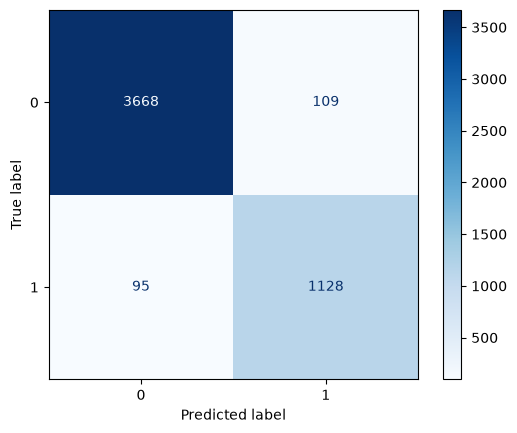

In [18]:
# After training, we can visualize the classification problem (amount of correctly classified items), false positives, and false negatives. 
# Collect final predictions on test set
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for x_batch, y_batch in test_dl:
        preds = (model(x_batch)[:, 0] >= 0.5).int()
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

# Compute and plot confusion matrix
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.show()